# Tiền xử lý, biểu đồ và dự đoán
Kết quả hiển thị trực tiếp trong VS Code. Các ô mã có thể chạy lại bằng kernel Python của dự án.

Biểu đồ kiểm thử đọc kết quả đã lưu; ô dự đoán mẫu gọi mô hình Random Forest đã huấn luyện.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import joblib

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reports/features.csv").exists())
sys.path.insert(0, str(ROOT / "app"))
sys.path.insert(0, str(ROOT / "src"))
from prediction import read_csv, predict
from input_audit import audit_frame
from battery_soh.features import FEATURES


## 1. Tiền xử lý
Đọc mẫu CSV, kiểm tra cấu trúc và từng chu kỳ. Có thể thay `file_path` bằng đường dẫn file của bạn.

In [2]:
file_path = ROOT / "examples/chu_ky_mau_SDU.csv"
frame = read_csv(file_path.read_bytes(), phase_code=0)
print("File:", file_path.name, "| Số dòng:", len(frame))
display(frame.head(10))
schema, checks, issue = audit_frame(frame)
display(schema)
display(checks)
if issue:
    print(issue)


cycle,time,terminal_voltage,terminal_current,temperature,battery,phase,phase_code,capacity,SOH
1,0.0000,4.173096,-0.479990,24.714846,SDU_01,primary,0,2.421768,1.00907
1,9.9999,4.170502,-0.479989,24.722500,SDU_01,primary,0,2.421768,1.00907
1,20.0006,4.168451,-0.479991,24.727440,SDU_01,primary,0,2.421768,1.00907
1,30.0010,4.166823,-0.479991,24.734112,SDU_01,primary,0,2.421768,1.00907
1,39.9997,4.165337,-0.479990,24.739520,SDU_01,primary,0,2.421768,1.00907
1,50.0012,4.164008,-0.479990,24.734790,SDU_01,primary,0,2.421768,1.00907
1,60.0018,4.162840,-0.479990,24.740290,SDU_01,primary,0,2.421768,1.00907
1,70.0006,4.161819,-0.479991,24.733430,SDU_01,primary,0,2.421768,1.00907
1,80.0011,4.160784,-0.479991,24.739090,SDU_01,primary,0,2.421768,1.00907
1,90.0014,4.159816,-0.479990,24.734110,SDU_01,primary,0,2.421768,1.00907


Cột,Có trong file,Giá trị thiếu,Không phải số hoặc vô hạn
time,True,0,0
terminal_voltage,True,0,0
terminal_current,True,0,0
temperature,True,0,0
cycle,True,0,0
phase_code,True,0,0


battery,phase_code,cycle,measurement_count,status,error
SDU_01,0,1,12,Hợp lệ,


File: chu_ky_mau_SDU.csv | Số dòng: 12


## 2. Đặc trưng và dự đoán mẫu
Mẫu thuộc bộ dữ liệu huấn luyện. Kết quả kiểm thử pin giữ riêng ở phần tiếp theo.

In [3]:
artifact = joblib.load(ROOT / "artifacts/random_forest.joblib")
cycle = int(frame.cycle.iloc[0])
estimate, features, outside = predict(frame, cycle, artifact)
display(features.T.rename(columns={0: "Giá trị"}).rename_axis("Đặc trưng").reset_index())
print(f"SOH dự đoán: {estimate:.3f}%")
print("Đặc trưng ngoài miền:", outside)


Đặc trưng,Giá trị
phase_code,0.000000
cycle,1.000000
voltage_mean,4.164205
voltage_min,4.158051
voltage_max,4.173096
voltage_std,0.004556
voltage_slope,-0.000130
current_mean,-0.479990
current_std,0.000002
temperature_mean,24.736398


SOH dự đoán: 101.375%
Đặc trưng ngoài miền: []


## 3. Tín hiệu đầu vào

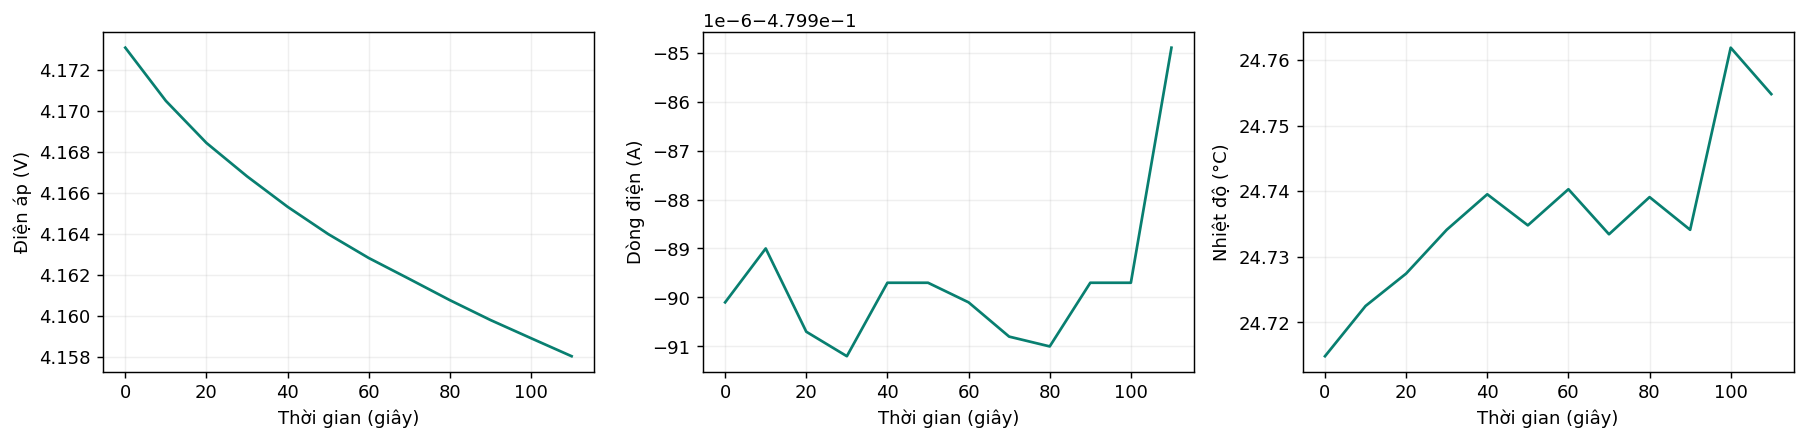

In [4]:
window = frame[frame.time <= 120].sort_values("time")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column, title in zip(axes, ["terminal_voltage", "terminal_current", "temperature"], ["Điện áp (V)", "Dòng điện (A)", "Nhiệt độ (°C)"]):
    ax.plot(window.time, window[column], color="#087f70")
    ax.set(xlabel="Thời gian (giây)", ylabel=title)
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


## 4. Thực tế và dự đoán trên pin kiểm thử
Thay `model_name`, `battery` và `phase` để xem phần khác.

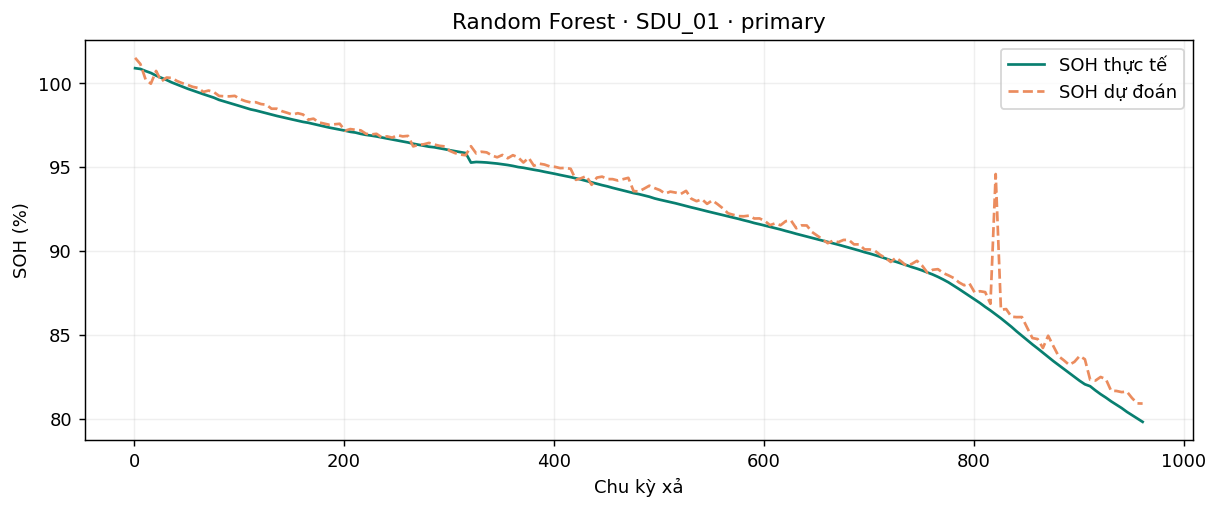

model,fold,battery,phase,cycle,actual_soh,predicted_soh
Random Forest,1,SDU_01,primary,1,100.907000,101.524055
Random Forest,1,SDU_01,primary,6,100.863375,101.159059
Random Forest,1,SDU_01,primary,11,100.738125,100.232964
Random Forest,1,SDU_01,primary,16,100.625083,99.984935
Random Forest,1,SDU_01,primary,21,100.466625,100.745710
Random Forest,1,SDU_01,primary,26,100.334417,100.118621
Random Forest,1,SDU_01,primary,31,100.203375,100.349644
Random Forest,1,SDU_01,primary,36,100.057292,100.325411
Random Forest,1,SDU_01,primary,41,99.934125,100.140815
Random Forest,1,SDU_01,primary,46,99.811083,100.014350


In [5]:
predictions = pd.read_csv(ROOT / "reports/predictions.csv")
model_name = "Random Forest"
battery = "SDU_01"
phase = "primary"
selected = predictions[(predictions.model == model_name) & (predictions.battery == battery) & (predictions.phase == phase)].sort_values("cycle")
if selected.empty:
    raise ValueError("Không có dữ liệu cho mô hình, pin và giai đoạn đã chọn.")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(selected.cycle, selected.actual_soh, label="SOH thực tế", color="#087f70")
ax.plot(selected.cycle, selected.predicted_soh, label="SOH dự đoán", color="#eb8c5e", linestyle="--")
ax.set(xlabel="Chu kỳ xả", ylabel="SOH (%)", title=f"{model_name} · {battery} · {phase}")
ax.legend()
ax.grid(alpha=.2)
plt.show()
display(selected.head(15))


## 5. So sánh mô hình
Chỉ số tổng hợp kiểm thử theo nhóm pin.

model,mae,rmse,r2
Mean baseline,13.2459,15.2489,-0.2809
Ridge,2.5818,3.2986,0.9332
Random Forest,1.6189,2.1572,0.9705
LightGBM,1.7344,2.2700,0.9677
GRU,2.1414,2.7180,0.9528


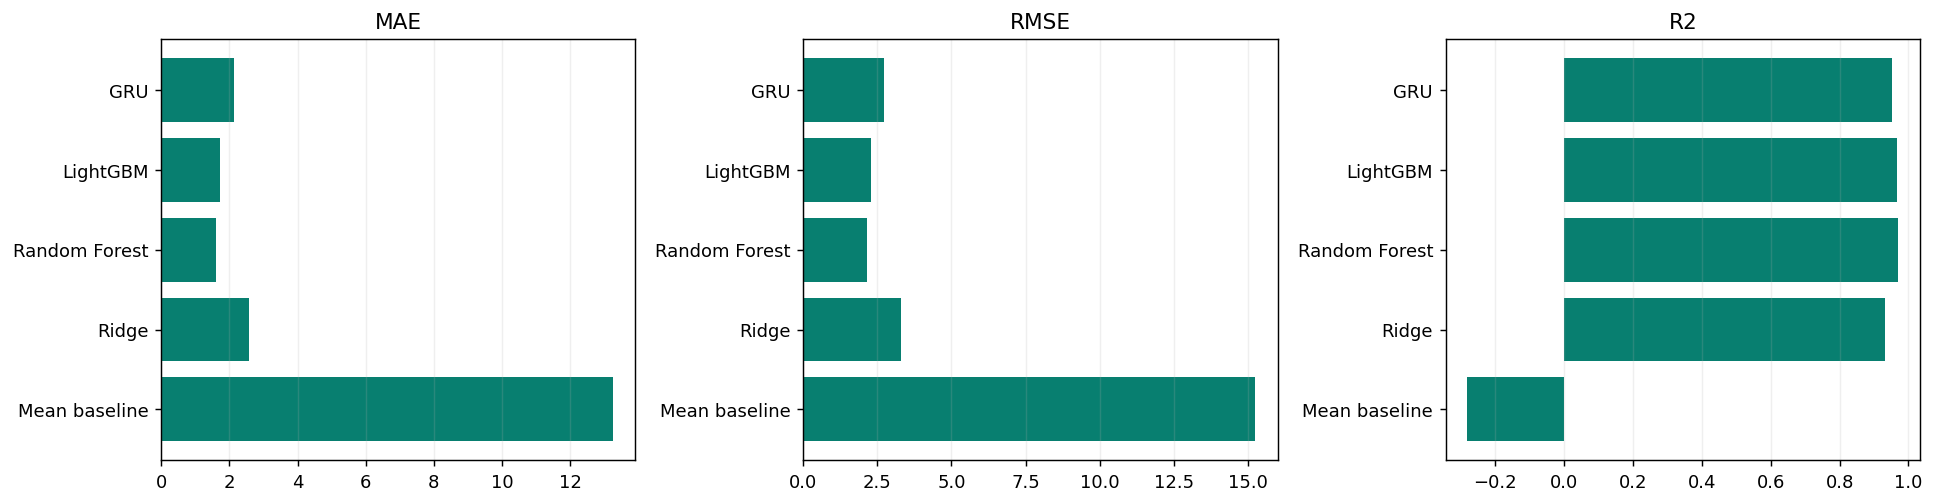

In [6]:
metrics = pd.read_csv(ROOT / "reports/metrics_summary.csv")
display(metrics.round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["mae", "rmse", "r2"]):
    ax.barh(metrics.model, metrics[metric], color="#087f70")
    ax.set_title(metric.upper())
    ax.grid(axis="x", alpha=.2)
fig.tight_layout()
plt.show()
